Analysis of IK's job application list

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import data
apps = pd.read_excel("after 260422 applied.xlsx")
apps.head(15)

,Date,Company,Role,Pay requested,More info,Unnamed: 5
0,260421.0,YO IT Consulting,Ai Trainer / Ai Data Trainer - Remote,NaN,NaN,NaN
1,NaN,Franklin Fitch,Software Engineer,NaN,NaN,NaN
2,NaN,Allstate,Quantum Algorithm Developer Expert,NaN,NaN,NaN
3,260422.0,GitHub,Senior Software Engineer,NaN,NaN,NaN
4,NaN,Stryker,Staff Software Engineer (Remote),NaN,NaN,NaN
5,NaN,Resourceful,Software Engineer,NaN,NaN,NaN
6,260423.0,Invisible Agency,Coding Specialist - Freelance AI Trainer Project,65/h,test failed 1st q,rejected
7,NaN,Mindrift,Physics Expert with Python / Freelance AI Trainer,76/h,2 tests done,rejected
8,NaN,GitHub,"Software Engineer II, Data Engineering",NaN,NaN,rejected
9,NaN,JobsAI,Software Engineer (Remote),40-150/h,AI interview,NaN


In [2]:
# Strip trailing spaces from string/object columns
str_cols = apps.select_dtypes(include=['object', 'string']).columns
apps[str_cols] = apps[str_cols].apply(lambda col: col.str.rstrip())

I shall change the name of column "Unnamed: 5" to "Response", and turn "Date" to datetime format.

In [3]:
apps = apps.rename(columns={"Unnamed: 5": "Response"})
apps.Date = pd.to_datetime(apps.Date, format='%y%m%d')
apps.head(15)

,Date,Company,Role,Pay requested,More info,Response
0,2026-04-21,YO IT Consulting,Ai Trainer / Ai Data Trainer - Remote,NaN,NaN,NaN
1,NaT,Franklin Fitch,Software Engineer,NaN,NaN,NaN
2,NaT,Allstate,Quantum Algorithm Developer Expert,NaN,NaN,NaN
3,2026-04-22,GitHub,Senior Software Engineer,NaN,NaN,NaN
4,NaT,Stryker,Staff Software Engineer (Remote),NaN,NaN,NaN
5,NaT,Resourceful,Software Engineer,NaN,NaN,NaN
6,2026-04-23,Invisible Agency,Coding Specialist - Freelance AI Trainer Project,65/h,test failed 1st q,rejected
7,NaT,Mindrift,Physics Expert with Python / Freelance AI Trainer,76/h,2 tests done,rejected
8,NaT,GitHub,"Software Engineer II, Data Engineering",NaN,NaN,rejected
9,NaT,JobsAI,Software Engineer (Remote),40-150/h,AI interview,NaN


In [4]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           164 non-null    datetime64[ns]
 1   Company        558 non-null    object        
 2   Role           558 non-null    object        
 3   Pay requested  372 non-null    object        
 4   More info      55 non-null     object        
 5   Response       5 non-null      object        
dtypes: datetime64[ns](1), object(5)
memory usage: 26.3+ KB


Looking though the data file I see that the column "Pay requested" contains (sparse) salary information up to a certain row and then it contains the link used to apply. Neither the sparse salary numbers nor the links are useful. For this reason I shall delete this column.

In [5]:
apps = apps.drop(columns = ['Pay requested'])
apps.head(15)

,Date,Company,Role,More info,Response
0,2026-04-21,YO IT Consulting,Ai Trainer / Ai Data Trainer - Remote,NaN,NaN
1,NaT,Franklin Fitch,Software Engineer,NaN,NaN
2,NaT,Allstate,Quantum Algorithm Developer Expert,NaN,NaN
3,2026-04-22,GitHub,Senior Software Engineer,NaN,NaN
4,NaT,Stryker,Staff Software Engineer (Remote),NaN,NaN
5,NaT,Resourceful,Software Engineer,NaN,NaN
6,2026-04-23,Invisible Agency,Coding Specialist - Freelance AI Trainer Project,test failed 1st q,rejected
7,NaT,Mindrift,Physics Expert with Python / Freelance AI Trainer,2 tests done,rejected
8,NaT,GitHub,"Software Engineer II, Data Engineering",NaN,rejected
9,NaT,JobsAI,Software Engineer (Remote),AI interview,NaN


Also looking through the dta file I see that initially the response is in column "Response", but after some point it is in column "More info". 

In [6]:
# Check contents in "More info" and "Response"
apps["More info"].value_counts(), apps["Response"].value_counts()

(More info
 R                                       49
 test failed 1st q                        1
 2 tests done                             1
 AI interview                             1
 finance                                  1
 The confirmation number is EVYdtJGA.     1
 LinkedIN removed the ad                  1
 Name: count, dtype: int64,
 Response
 rejected    5
 Name: count, dtype: int64)

Given this content in "More info", I shall pass the "R" to "Response", change "rejected" to "R" in "Response", and delete "More info".

In [7]:
apps.loc[apps["More info"] == 'R', "Response"] = 'R'
apps.loc[apps["Response"] == 'rejected', "Response"] = 'R'
apps.Response.value_counts()

Response
R    54
Name: count, dtype: int64

In [8]:
apps = apps.drop(columns = ['More info'])
apps.head(15)

,Date,Company,Role,Response
0,2026-04-21,YO IT Consulting,Ai Trainer / Ai Data Trainer - Remote,NaN
1,NaT,Franklin Fitch,Software Engineer,NaN
2,NaT,Allstate,Quantum Algorithm Developer Expert,NaN
3,2026-04-22,GitHub,Senior Software Engineer,NaN
4,NaT,Stryker,Staff Software Engineer (Remote),NaN
5,NaT,Resourceful,Software Engineer,NaN
6,2026-04-23,Invisible Agency,Coding Specialist - Freelance AI Trainer Project,R
7,NaT,Mindrift,Physics Expert with Python / Freelance AI Trainer,R
8,NaT,GitHub,"Software Engineer II, Data Engineering",R
9,NaT,JobsAI,Software Engineer (Remote),NaN


Currently only the first application of a day has a date. I shall use forward fill in order to have a date for each application. 

In [9]:
apps['Date'] = apps['Date'].ffill()
apps.head(15)

,Date,Company,Role,Response
0,2026-04-21,YO IT Consulting,Ai Trainer / Ai Data Trainer - Remote,NaN
1,2026-04-21,Franklin Fitch,Software Engineer,NaN
2,2026-04-21,Allstate,Quantum Algorithm Developer Expert,NaN
3,2026-04-22,GitHub,Senior Software Engineer,NaN
4,2026-04-22,Stryker,Staff Software Engineer (Remote),NaN
5,2026-04-22,Resourceful,Software Engineer,NaN
6,2026-04-23,Invisible Agency,Coding Specialist - Freelance AI Trainer Project,R
7,2026-04-23,Mindrift,Physics Expert with Python / Freelance AI Trainer,R
8,2026-04-23,GitHub,"Software Engineer II, Data Engineering",R
9,2026-04-23,JobsAI,Software Engineer (Remote),NaN


Now the data are ready for further investigation.
To how many different roles has IK applied, and how many applications has he submitted for each role?

In [10]:
apps.Role.value_counts().count()

346

In [11]:
roles = apps.Role.value_counts()
roles

Role
Software Engineer                                        103
Senior Software Engineer                                  18
Software Engineer II                                      10
Junior Software Engineer                                   8
Software Developer                                         8
                                                        ... 
Sr. Software Engineer I                                    1
Software Engineer L3                                       1
Software Engineer II, Backend (ML Training & Serving)      1
Scientific and Technical Consulting                        1
Physics Expert                                             1
Name: count, Length: 346, dtype: int64

Show the 20 most applied-to roles.

In [12]:
roles[:20]

Role
Software Engineer                       103
Senior Software Engineer                 18
Software Engineer II                     10
Junior Software Engineer                  8
Software Developer                        8
Data Scientist                            6
Software Engineer (All Levels)            5
Software Engineer I                       5
Senior Software Developer                 5
Software Engineer III                     5
Software Engineer, C++                    4
Staff Software Engineer                   4
Forward Deployed Engineer                 3
Senior Software Engineer, Backend         3
Python Developer                          3
C++ Developer                             3
Software Engineer, Backend (Trading)      3
Software Development Engineer             3
Software Engineer (Remote)                3
Software Engineer, Backend                3
Name: count, dtype: int64

To how many different companies has IK applied, and how many applications has he submitted to each company?

In [13]:
apps.Company.value_counts()

Company
Ladders                      20
Crossing Hurdles             17
Helic & Co.                   6
Stealth Startup               5
Primordial Labs               5
                             ..
Kinaxis                       1
Upamind                       1
vRad (Virtual Radiologic)     1
Trimble                       1
Clera                         1
Name: count, Length: 422, dtype: int64

List all the companies to which IK applied more than once.

In [14]:
counts = apps.Company.value_counts()
counts[counts > 1]

Company
Ladders             20
Crossing Hurdles    17
Helic & Co.          6
Stealth Startup      5
Primordial Labs      5
                    ..
Curana Health        2
Cutsforth            2
Edge Focus           2
Ascensus             2
GitHub               2
Name: count, Length: 71, dtype: int64

List all the companies to which IK applied more than twice.

In [15]:
counts[counts > 2]

Company
Ladders                            20
Crossing Hurdles                   17
Helic & Co.                         6
Stealth Startup                     5
Primordial Labs                     5
Turing                              5
CodeGeniusRecruit                   4
Jobgether                           4
BrothersTech                        4
Airbnb                              4
Fieldguide                          4
EnergyHub                           3
Rise Technical                      3
Tradeweb                            3
Ocient                              3
Nira Energy                         3
Oracle · United States (Remote)     3
Phantom                             3
Atomic Invest                       3
Jobs Ai                             3
Name: count, dtype: int64

How many applications has IK submitted in each month?

In [16]:
apps.groupby(apps.Date.dt.to_period('M')).size()

Date
2026-04     36
2026-05    107
2026-06     97
2026-07    100
2026-08     63
2026-09     52
2026-10     65
2026-11     38
Freq: M, dtype: int64

Show the number of applications in each month in a bar graph.

<Axes: title={'center': 'Applications in each month'}, xlabel='Month', ylabel='Number of applications'>

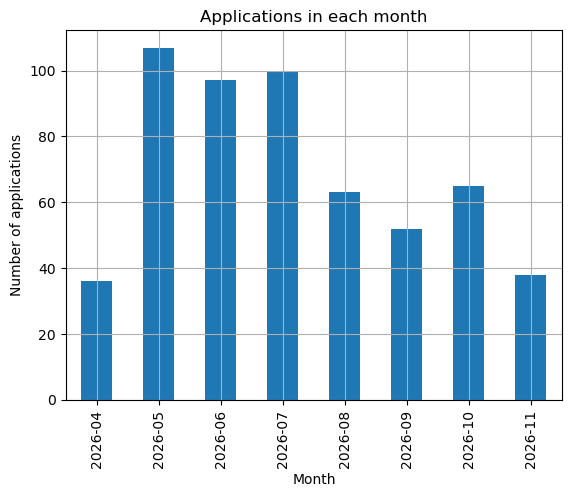

In [17]:
apps.groupby(apps.Date.dt.to_period('M')).size().plot(kind='bar', 
                                                      grid=True, 
                                                      xlabel="Month", 
                                                      ylabel="Number of applications", 
                                                      title="Applications in each month")

Which companies have rejected IK?

In [18]:
apps.Company[apps.Response == 'R'].value_counts()

Company
One Call                           2
Tilt                               2
Intuitive Machines                 2
Ascensus                           2
Invisible Agency                   1
Indeed                             1
GRID eSports GmbH - Malta, MT      1
Info Incognito                     1
Oracle · United States (Remote)    1
Aledade                            1
New Relic                          1
Ladders                            1
Horace Mann                        1
Inovalon                           1
NinjaOne                           1
TEAM Academics Tutoring            1
Upstart                            1
Airbnb                             1
Nextech Systems                    1
Discord                            1
Stealth Startup                    1
Temu                               1
Benda Infotech                     1
Spinplay Games                     1
Mobius Logic                       1
Modular, a Qualcomm company        1
enGen/Hignmark                